Epoch 1/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 1.1047 - val_loss: 0.9609
Epoch 2/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7844 - val_loss: 0.6990
Epoch 3/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6205 - val_loss: 0.6306
Epoch 4/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5471 - val_loss: 0.5913
Epoch 5/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4794 - val_loss: 0.5178
Epoch 6/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4599 - val_loss: 0.5252
Epoch 7/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4474 - val_loss: 0.5056
Epoch 8/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4381 - val_loss: 0.4981
Epoch 9/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4346 - val_loss: 0.4976
Epoch 10/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4293 - val_loss: 0.4911
Epoch 11/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4252 - val_loss: 0.4870
Epoch 12/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.

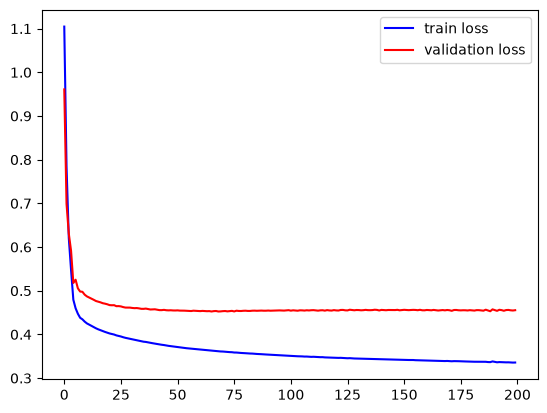

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step

Accuracy of the test data = 0.84


In [1]:
# [MXDL-5-01] 2.wb_regularizer.py - Keras regularizer
import numpy as np
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model
from tensorflow.keras import optimizers
from tensorflow.keras import regularizers
import matplotlib.pyplot as plt
import pickle

# Read a saved dataset
with open('data/blobs.pkl', 'rb') as f:
    x_train, x_test, y_train, y_test = pickle.load(f)

# Create an ANN model.
n_input = x_train.shape[1]   # number of input neurons
n_output = 1                 # number of output neurons
n_hidden = 32                # number of hidden neurons

# Create Adam optimizer and L1, L2 regularizer
adam = optimizers.Adam(learning_rate=0.005)
L1 = regularizers.l1(0.001)
L2 = regularizers.l2(0.001)
L12 = regularizers.l1_l2(0.001)

# The data is simple, but we intentionally added many
# hidden layers to the model to demonstrate the effect
# of regularization.
x_input = Input(batch_shape=(None, n_input))
h1 = Dense(n_hidden, activation='relu',
           kernel_regularizer=L1,
           bias_regularizer=L1)(x_input)

h2 = Dense(n_hidden, activation='relu',
           kernel_regularizer=L2,
           bias_regularizer=L2)(h1)

h3 = Dense(n_hidden, activation='relu',
           kernel_regularizer=L12,
           bias_regularizer=L12)(h2)

h4 = Dense(n_hidden, activation='relu',
           kernel_regularizer=L1,
           bias_regularizer=L12)(h3)

h5 = Dense(n_hidden, activation='relu',
           kernel_regularizer=L12,
           bias_regularizer=L2)(h4)

y_output = Dense(n_output, activation='sigmoid',
                 kernel_regularizer=L12,
                 bias_regularizer=L2)(h5)
model = Model(x_input, y_output)
model.compile(loss='binary_crossentropy', optimizer=adam)

# training
f = model.fit(x_train, y_train,
              validation_data=(x_test, y_test),
              epochs=200, batch_size=20)

# Visually see the loss history
plt.plot(f.history['loss'], c='blue', label='train loss')
plt.plot(f.history['val_loss'], c='red', label='validation loss')
plt.legend()
plt.show()

# Check the accuracy of the test data
y_pred = (model.predict(x_test) > 0.5) * 1
acc = (y_pred == y_test).mean()
print("\nAccuracy of the test data = {:.2f}".format(acc))